# Corrected real-data covariate-shift experiments

This notebook reproduces **Table 4** for Airfoil and Concrete under **both β settings** with ten seeded repetitions each. IW now weights source training and validation losses; all methods are scored with ordinary MSE on the same shifted target test set.

The committed results are displayed by default. See [README-real-data.md](README-real-data.md) for the protocol, original V2 checkpoint, package versions, and command-line rerun. The synthetic-study Figures 4/15 are separate from this correction.

**KRR oracle caveat:** the real-data benchmark selects its penalty with the test labels. It is an optimistic test-label oracle, not the true-conditional-mean oracle used for synthetic data.

In [1]:
from pathlib import Path
import os
from IPython.display import display, Image, Markdown
from real_data_experiment import HERE, Config, run_experiment
from validate_real_data_results import validate

RERUN = False
results_dir = HERE / "results" / "real_data"
if RERUN:
    # Set this to the original TabPFNv2 checkpoint before reproducing.
    model_path = os.environ.get("TABPFN_V2_MODEL_PATH")
    if not model_path:
        raise ValueError("Set TABPFN_V2_MODEL_PATH to tabpfn-v2-regressor.ckpt")
    os.environ.setdefault("TABPFN_ALLOW_CPU_LARGE_DATASET", "1")
    os.environ.setdefault("TABPFN_DISABLE_TELEMETRY", "1")
    results_dir = HERE / "results" / "real_data_rerun"
    run_experiment(results_dir, model_path, Config())

validation = validate(results_dir)
validation

Verified 40 runs, 240 method-level MSEs, all seeds/draws/indices, and all means/SEs.


{'runs': 40, 'mse_values': 240, 'iw_refit_checks': 0, 'status': 'passed'}

In [2]:
# Tables and figures are generated from the same full-precision results.
# Regenerate exports after an explicit rerun; otherwise show committed artifacts.
if RERUN:
    from export_real_data_results import export_results
    export_results(results_dir)
display(Markdown((results_dir / "table4.md").read_text()))

# Corrected real-data covariate-shift results

Mean target test MSE ± standard error across 10 seeded 70/30 splits; lower is better.

| Dataset | Shift | KRR test-label oracle | PL | Naive XGBoost | IW XGBoost | TabPFNv2 |
|---|---|---:|---:|---:|---:|---:|
| Airfoil | β₁ | 12.60 ± 1.51 | 14.12 ± 1.66 | 11.64 ± 3.93 | 11.74 ± 3.90 | **3.11 ± 0.76** |
| Airfoil | β₂ | 8.47 ± 0.55 | 8.99 ± 0.62 | 3.57 ± 0.44 | 3.60 ± 0.19 | **1.65 ± 0.15** |
| Concrete | β₁ | 47.54 ± 13.16 | 97.23 ± 20.44 | 5.73 ± 1.40 | 5.28 ± 0.71 | **2.56 ± 0.45** |
| Concrete | β₂ | 61.12 ± 22.44 | 120.60 ± 31.10 | 7.80 ± 1.05 | 6.99 ± 0.85 | **4.95 ± 0.67** |

The KRR test-label oracle selects its penalty using the same target test labels used for evaluation; it is an optimistic benchmark, not the true-conditional-mean oracle from the synthetic experiment.

IW uses exponential density-ratio weights during both training and source-validation scoring. Every method is evaluated with ordinary MSE on the same resampled target observations. XGBoost uses five-fold CV with the original 32-candidate grid. TabPFN uses the V2 checkpoint and eight ensemble estimators.

Features retain the public notebook's preprocessing: raw covariates standardized using source-training means and standard deviations; no log transforms. The β vectors operate on these standardized covariates. Both settings share each source split and baseline fits. Resampling is seeded separately for each dataset, shift, and repetition.

Reported SE is the sample SD of the ten split-level MSEs divided by √10. Repeated splits overlap and share a finite dataset, so these SEs describe variability across repetitions and are not population-level confidence intervals. Bold identifies the smallest mean, without a significance claim.

Full precision and the extra KRR source-selected comparator: `summary.csv`. Individual errors: `per_split_mse.csv`. Weight and resampling diagnostics: `diagnostics.csv`. Raw predictions, CV traces, indices, versions, checkpoint checksum, and protocol are retained in the results directory.


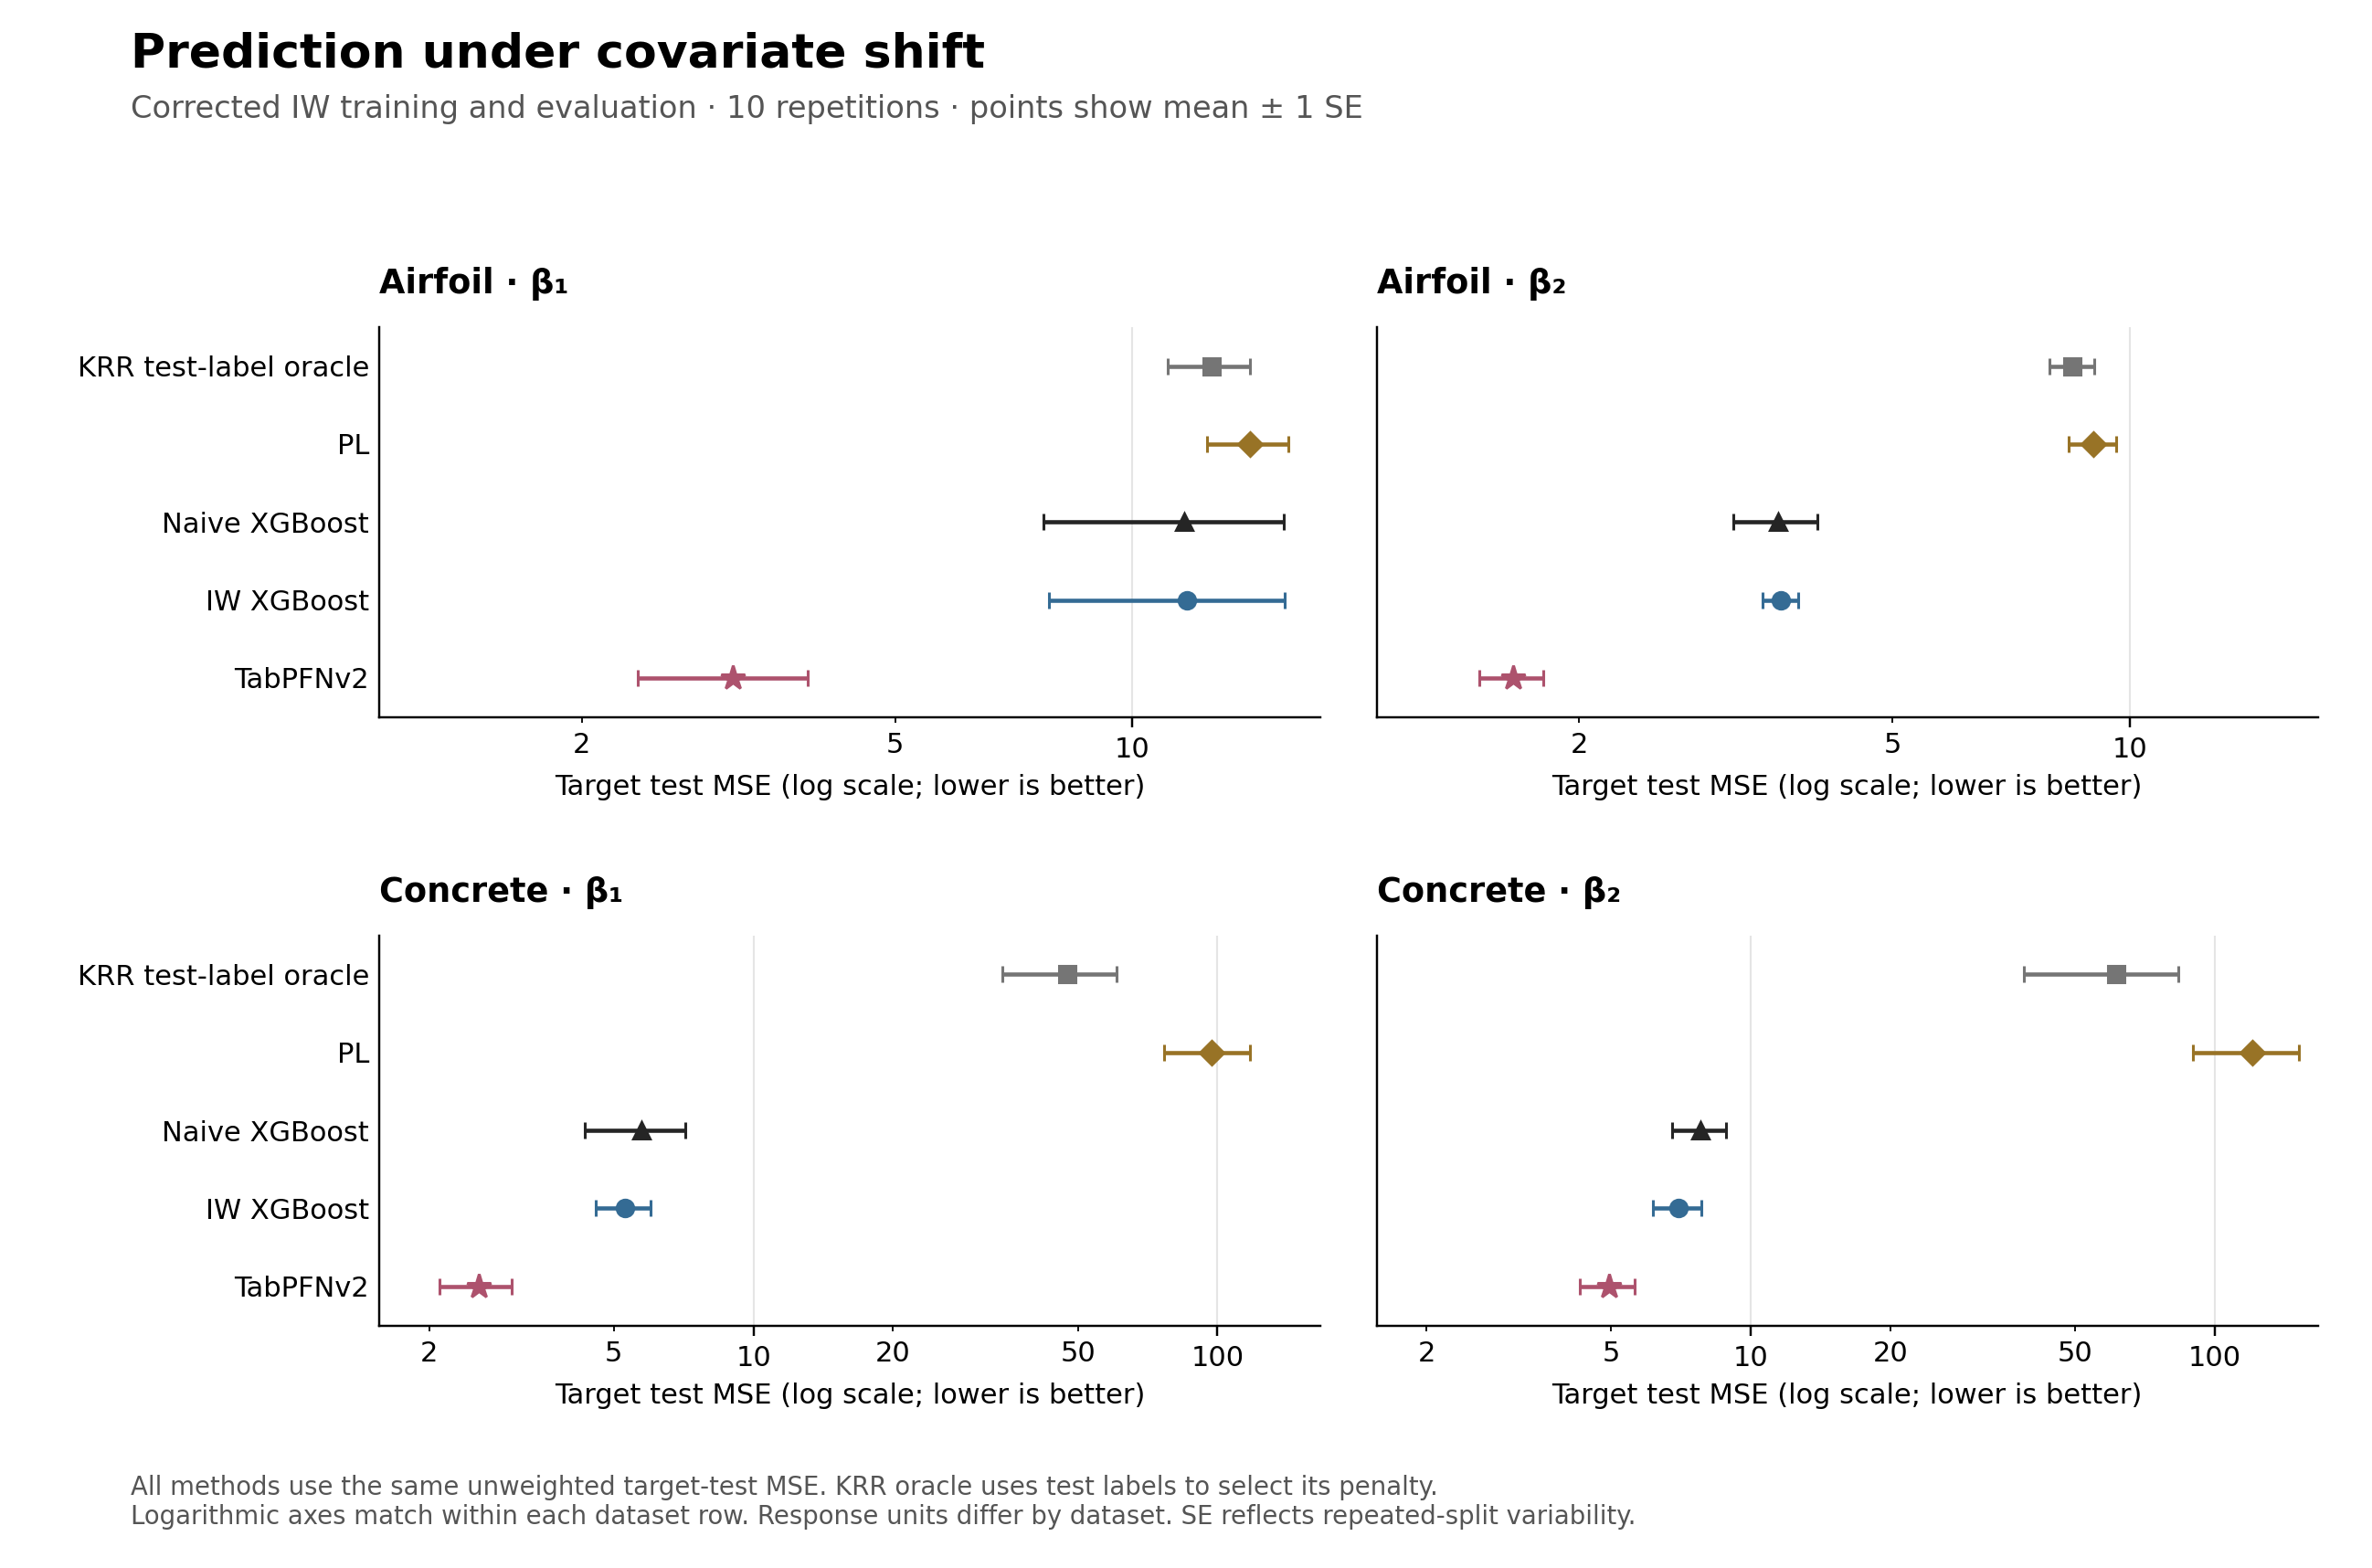

In [3]:
display(Image(filename=str(results_dir / "real_data_comparison.png")))

In [4]:
import pandas as pd
summary = pd.read_csv(results_dir / "summary.csv")
display(summary)
diagnostics = pd.read_csv(results_dir / "diagnostics.csv")
display(diagnostics.groupby(["dataset", "setting"])[
    ["training_weight_ess", "target_reservoir_ess", "n_unique_target"]
].agg(["min", "median", "max"]))

,dataset,setting,method,mean,std,count,se
0,airfoil,beta1,krr_test_oracle,12.604752,4.771315,10,1.508822
1,airfoil,beta1,pl,14.118251,5.262000,10,1.663990
2,airfoil,beta1,krr_naive,18.032211,9.058405,10,2.864519
3,airfoil,beta1,xgb,11.640534,12.419641,10,3.927435
4,airfoil,beta1,iw,11.744508,12.317337,10,3.895084
5,airfoil,beta1,tabpfn,3.113269,2.397720,10,0.758226
6,airfoil,beta2,krr_test_oracle,8.469773,1.746096,10,0.552164
7,airfoil,beta2,pl,8.994969,1.950633,10,0.616844
8,airfoil,beta2,krr_naive,10.121416,3.919156,10,1.239346
9,airfoil,beta2,xgb,3.573975,1.377012,10,0.435450


training_weight_ess                          \
                                 min      median         max   
dataset  setting                                               
airfoil  beta1            112.432474  122.456318  146.720269   
         beta2            139.455690  142.800648  164.901450   
concrete beta1              2.081161    2.910794    5.710834   
         beta2             15.978346   21.833785   29.237389   

                 target_reservoir_ess                       n_unique_target  \
                                  min     median        max             min   
dataset  setting                                                              
airfoil  beta1              42.620312  54.363559  70.686828             126   
         beta2              46.843888  58.947748  70.747092             142   
concrete beta1               1.618250   3.678267   6.611066              10   
         beta2               6.374222   8.259576  16.211682              51   

                              
                 median  max  
dataset  setting              
airfoil  beta1    134.0  157  
         beta2    156.5  165  
concrete beta1     20.5   29  
         beta2     67.5   89